# Лабораторная работа №2

## Цели и задачи

Научиться строить ядерные оценки плотности распределения (KDE) и
сравнить ее с гистограммой, оценить потери информации при построении оценок плотности
распределения в сравнении с эмпирической функцией распределения, оценить
статистическую точность оценок квантилей по оценкам плотности в сравнении с оценками
квантили по эмпирической функции распределения.

## 1. Построение гистограмм, графиков KDE и квантилей

### Идея расчёта квантили по гистограмме

Допустим, на текущий момент накоплена площадь $s < p$. 

Происходит переход к следующему столбику. Тогда обновлённая накопленная площадь будет $S = s + h \cdot (x_{i+1} - x_{i})$. 

Пусть $S \ge p$. Значит, квантиль находится в промежутке $(x_{i}, x_{i+1}]$. Следовательно, существует такой $x$, что $s + h \cdot (x-x_{i}) = p$. 

Выразив из данного уравнения $x$, можно получить следующее выражение $$x = \frac{p-s}{h}+x_{i}$$ 

In [1]:
def get_histogram_quantile(data, p):
    bins = int(1 + 1.59 * np.log(len(data)))
    hist, edges = np.histogram(data, bins=bins, density=True)
    prev_square = 0
    square = 0
    quantile = edges[0]
    for i, h in enumerate(hist):
        prev_square = square
        square += h * (edges[i+1] - edges[i])
        if square >= p:
            quantile = edges[i] + (p - prev_square) / h
            break
    return quantile

### Идея расчёта квантили по KDE

Для подсчёта площади под графиком ядерной оценки плотности используется метод трапеций.

Допустим, на текущий момент накоплена площадь $s < p$.

Происходит переход к следующей трапеции. Тогда обновлённая накопленная площадь будет:

$$
S = s + \frac{(x_{i+1} - x_i)(y_i + y_{i+1})}{2}
$$

Пусть $S \geq p$. Следовательно, квантиль находится внутри текущей трапеции.

Необходимо найти такую точку $x'$, чтобы:

$$
s + \frac{(x' - x_i)(y_i + y')}{2} = p
$$

Поскольку верхняя сторона трапеции представляет собой отрезок прямой, проходящей через точки $(x_i,y_i)$ и $(x_{i+1},y_{i+1})$, имеем:

$$
y' = ax' + b
$$

где

$$
a = \frac{y_{i+1} - y_i}{x_{i+1} - x_i}
$$

$$
b = y_i - ax_i
$$

Подставив выражение для $y'$ в исходное уравнение, можно получить следующее выражение:

$$
s + \frac{(x' - x_i)(y_i + ax' + b)}{2} = p
$$

Из умножения обеих частей на 2 следует, что:

$$
2s + (x' - x_i)(y_i + ax' + b) = 2p
$$

Далее следует раскрыть скобки:

$$
2s + ax'^2 + (y_i + b - ax_i)x' - x_i(y_i + b) = 2p
$$

Затем перенести всё в левую часть:

$$
ax'^2 + (y_i + b - ax_i)x' + 2s - x_i(y_i + b) - 2p = 0
$$

Решая уравнение относительно $x'$, следует оставить только то решение, которое лежит между $x_{i}$ и $x_{i+1}$.

In [2]:
def get_kde_quantile(x, y, p):
    square = 0
    prev_square = 0
    m = 0
    for i in range(len(x)-1):
        prev_square = square
        h = x[i + 1] - x[i]
        square += (y[i] + y[i + 1]) * h / 2
        if square >= p:
            a = (y[i + 1] - y[i]) / (x[i + 1] - x[i])
            b = y[i] - a * x[i]
            d = (y[i] - a * x[i] + b) ** 2 - 4 * a * (2 * prev_square - x[i] * y[i] - b * x[i] - 2 * p)
            m_1 = (-y[i] + a * x[i] - b - np.sqrt(d)) / (2 * a)
            m_2 = (-y[i] + a * x[i] - b + np.sqrt(d)) / (2 * a)
            if x[i] <= m_1 <= x[i + 1]:
                m = m_1
            else:
                m = m_2
            break
    return m

In [3]:
def plot_histograms(data, axes, n, d):
    p_arr = [0.01, 0.05, 0.5]
    colors = ['red', 'orange', 'green']
    bins = int(1 + 1.59 * np.log(size))
    hist_quantiles = []
    kde_quantiles = []
    ax = sns.histplot(data=data, ax=axes[n][d], bins=bins, stat='density', kde=True)
    x, y = ax.lines[0].get_data()
    for p in p_arr:
        hist_quantiles.append(get_histogram_quantile(data, p))
        kde_quantiles.append(get_kde_quantile(x, y, p))
    for i, color in enumerate(colors):
        axes[n][d].axvline(hist_quantiles[i], color=color, linestyle='--', label=f'Histogram quantile {p_arr[i]}: {hist_quantiles[i]:.3f}')
        axes[n][d].axvline(kde_quantiles[i], color=color, label=f'KDE quantile {p_arr[i]}: {kde_quantiles[i]:.3f}')
    if d == 0:
        axes[n][d].set_title('Uniform distribution')
    else:
        axes[n][d].set_title('Normal distribution')
    axes[n][d].legend()

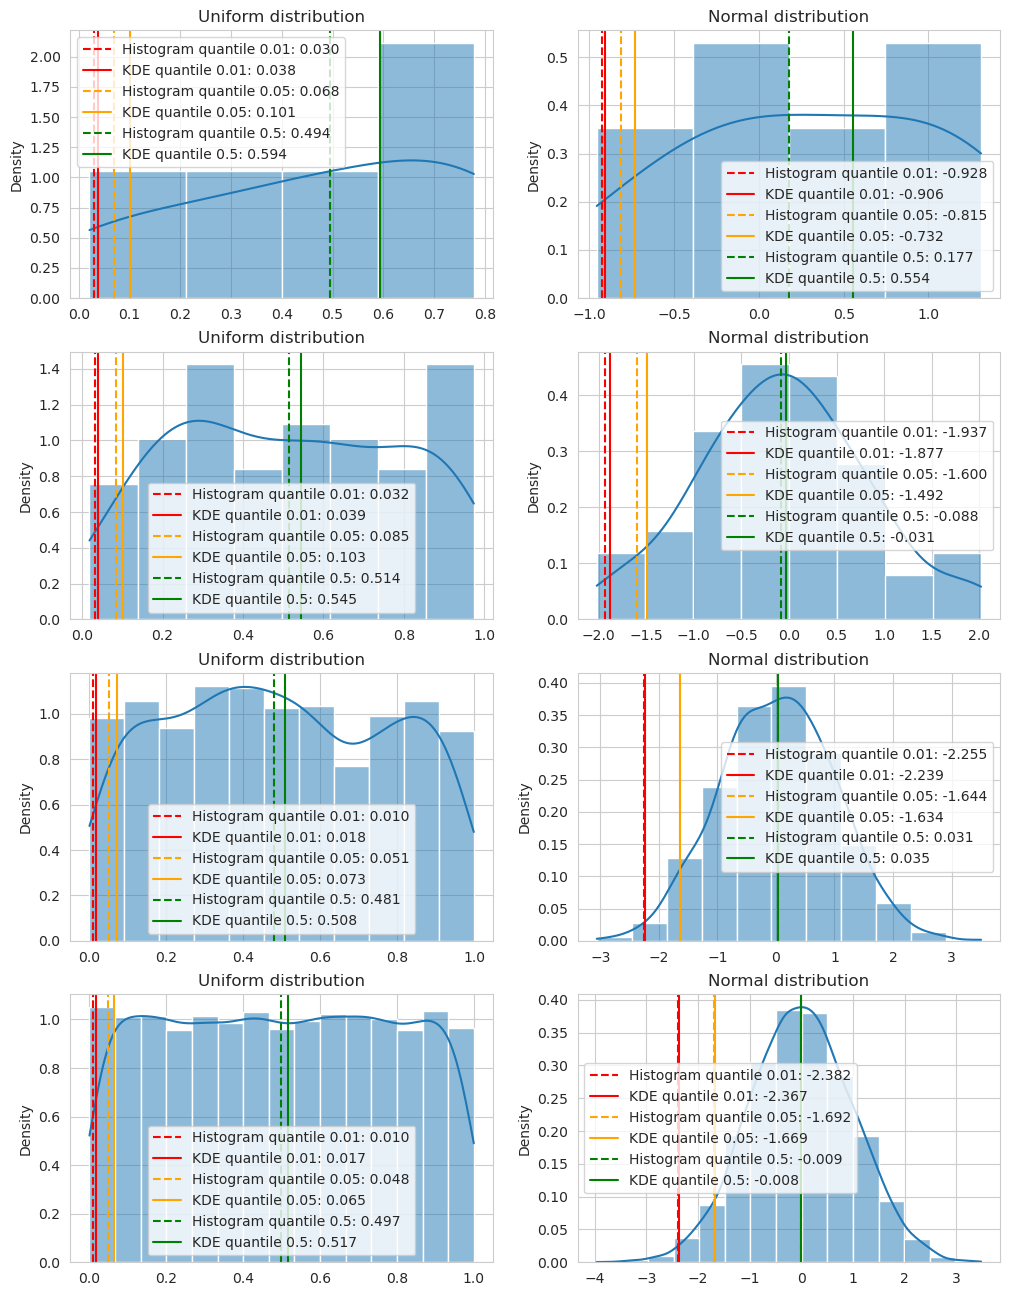

In [4]:
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt 

sns.set_style("whitegrid")
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
for i in range(4):
    size = 10**(i+1)
    uniform_distr = np.random.uniform(size=size)
    normal_distr = np.random.normal(size=size)
    plot_histograms(uniform_distr, axes, i, 0)
    plot_histograms(normal_distr, axes, i, 1)

In [19]:
from scipy.stats import gaussian_kde

distributions = {
    "Uniform": np.random.uniform,
    "Normal": np.random.normal
}

n_arr = [10, 100, 1000, 10000]
p_arr = [0.01, 0.05, 0.5]

for name, distribution in distributions.items():
    print(f"\nDistribution: {name}")
    for n in n_arr:
        print(f"N: {n}")
        for p in p_arr:
            cdf_quantile = []
            hist_quantile = []
            kde_quantile = []
            for _ in range(1000):
                data = distribution(size=n)
                x = np.linspace(data.min(), data.max(), 200)
                y = gaussian_kde(data)(x)
                cdf_quantile.append(np.quantile(data, p))
                hist_quantile.append(get_histogram_quantile(data, p))
                kde_quantile.append(get_kde_quantile(x, y, p))
            for method, quantiles in {
                "CDF": cdf_quantile,
                "Histogram": hist_quantile,
                "KDE": kde_quantile
            }.items():
                print(f"\t{method}")
                print(f"\tmean quantile {p}: {np.mean(quantiles)}")
                print(f"\tvar quantile: {np.var(quantiles)}")


Distribution: Uniform
N: 10
	CDF
	mean quantile 0.01: 0.0969273150255579
	var quantile: 0.005997654337098667
	Histogram
	mean quantile 0.01: 0.09691528007191985
	var quantile: 0.005977237845565727
	KDE
	mean quantile 0.01: 0.10407037083072834
	var quantile: 0.005901789149834315
	CDF
	mean quantile 0.05: 0.13001244026333678
	var quantile: 0.0073807805771930295
	Histogram
	mean quantile 0.05: 0.1305427055929146
	var quantile: 0.006605929328675382
	KDE
	mean quantile 0.05: 0.16034052322615344
	var quantile: 0.006413219416514042
	CDF
	mean quantile 0.5: 0.49895307862485877
	var quantile: 0.01961689896335866
	Histogram
	mean quantile 0.5: 0.49718272762228183
	var quantile: 0.019161306229684726
	KDE
	mean quantile 0.5: 0.6147515371201312
	var quantile: 0.009716466192662358
N: 100
	CDF
	mean quantile 0.01: 0.01996222603615076
	var quantile: 0.00020400002125295998
	Histogram
	mean quantile 0.01: 0.019784956558077462
	var quantile: 0.00011566498642553855
	KDE
	mean quantile 0.01: 0.02817180179

### Равномерное распределение

#### Средние значения оценок квантилей

| N | Метод | 1% | 5% | 50% |
|---:|---|---:|---:|---:|
| 10 | CDF | 0.096927 | 0.130012 | 0.498953 |
| 10 | Histogram | 0.096915 | 0.130543 | 0.497183 |
| 10 | KDE | 0.104070 | 0.160341 | 0.614752 |
| 100 | CDF | 0.019962 | 0.058452 | 0.500722 |
| 100 | Histogram | 0.019785 | 0.059638 | 0.500846 |
| 100 | KDE | 0.028172 | 0.087690 | 0.551149 |
| 1000 | CDF | 0.011299 | 0.050670 | 0.499647 |
| 1000 | Histogram | 0.011041 | 0.050749 | 0.499561 |
| 1000 | KDE | 0.019206 | 0.073594 | 0.528932 |
| 10000 | CDF | 0.010081 | 0.050024 | 0.500263 |
| 10000 | Histogram | 0.010083 | 0.050042 | 0.500287 |
| 10000 | KDE | 0.017461 | 0.066801 | 0.518618 |
| **Теория** | | **0.010000** | **0.050000** | **0.500000** |

#### Дисперсии оценок квантилей

| N | Метод | 1% | 5% | 50% |
|---:|---|---:|---:|---:|
| 10 | CDF | 0.00599765 | 0.00738078 | 0.01961690 |
| 10 | Histogram | 0.00597724 | 0.00660593 | 0.01916131 |
| 10 | KDE | 0.00590179 | 0.00641322 | 0.00971647 |
| 100 | CDF | 0.00020400 | 0.00051590 | 0.00245726 |
| 100 | Histogram | 0.00011566 | 0.00028791 | 0.00225210 |
| 100 | KDE | 0.00011419 | 0.00021121 | 0.00160665 |
| 1000 | CDF | 0.00001039 | 0.00004761 | 0.00026430 |
| 1000 | Histogram | 0.00000185 | 0.00002709 | 0.00024651 |
| 1000 | KDE | 0.00000249 | 0.00001825 | 0.00019803 |
| 10000 | CDF | 0.00000097 | 0.00000467 | 0.00002424 |
| 10000 | Histogram | 0.00000016 | 0.00000350 | 0.00002235 |
| 10000 | KDE | 0.00000026 | 0.00000209 | 0.00002009 |

---

### Нормальное распределение

#### Средние значения оценок квантилей

| N | Метод | 1% | 5% | 50% |
|---:|---|---:|---:|---:|
| 10 | CDF | -1.481811 | -1.290132 | -0.010455 |
| 10 | Histogram | -1.488779 | -1.323383 | -0.011320 |
| 10 | KDE | -1.462743 | -1.223138 | 0.297377 |
| 100 | CDF | -2.149661 | -1.595264 | -0.002899 |
| 100 | Histogram | -2.240991 | -1.685062 | -0.003132 |
| 100 | KDE | -2.186200 | -1.657948 | 0.029419 |
| 1000 | CDF | -2.305173 | -1.636745 | 0.002487 |
| 1000 | Histogram | -2.386063 | -1.688811 | 0.002176 |
| 1000 | KDE | -2.358288 | -1.682500 | 0.004921 |
| 10000 | CDF | -2.323096 | -1.644026 | -0.000439 |
| 10000 | Histogram | -2.375794 | -1.680125 | -0.000231 |
| 10000 | KDE | -2.351163 | -1.664275 | -0.000211 |
| **Теория** | | **-2.326348** | **-1.644854** | **0.000000** |

#### Дисперсии оценок квантилей

| N | Метод | 1% | 5% | 50% |
|---:|---|---:|---:|---:|
| 10 | CDF | 0.34209256 | 0.23916015 | 0.13290540 |
| 10 | Histogram | 0.35099429 | 0.25945345 | 0.13228574 |
| 10 | KDE | 0.34050550 | 0.23205575 | 0.11788355 |
| 100 | CDF | 0.10176625 | 0.04050935 | 0.01532261 |
| 100 | Histogram | 0.10490498 | 0.03937145 | 0.01417759 |
| 100 | KDE | 0.08274366 | 0.02886401 | 0.01181294 |
| 1000 | CDF | 0.01410770 | 0.00428049 | 0.00155728 |
| 1000 | Histogram | 0.01334195 | 0.00423914 | 0.00136934 |
| 1000 | KDE | 0.00990119 | 0.00339892 | 0.00127846 |
| 10000 | CDF | 0.00133034 | 0.00043596 | 0.00015866 |
| 10000 | Histogram | 0.00174405 | 0.00065454 | 0.00014568 |
| 10000 | KDE | 0.00107209 | 0.00037242 | 0.00014038 |

## Выводы

1. С увеличением объёма выборки дисперсия оценок квантилей уменьшается для обоих рассматриваемых распределений.

2. Оценивание квантилей с помощью KDE может приводить к систематическому смещению относительно теоретических значений. Причиной является ограничение области численного интегрирования, вследствие чего площадь под рассматриваемым участком KDE оказывается меньше единицы. Расширение области интегрирования позволяет уменьшить эту ошибку, однако для равномерного распределения оценки малых квантилей могут становиться отрицательными. Это связано с использованием гауссовых ядер, плотность которых выходит за границы исходного распределения.

3. Для обоих распределений в большинстве проведённых экспериментов дисперсия оценок квантилей, полученных через CDF, оказалась больше, чем у других методов. Однако меньшая дисперсия не всегда свидетельствует о большей точности оценивания.

4. Для обоих распределений средние значения оценок квантилей, полученных через CDF, в большинстве случаев оказались ближе к теоретическим значениям. Это особенно заметно с увеличением объёма выборки.